In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

# Project directories
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

DATA_DIR = PROJECT_ROOT / "data" / "raw" / "physionet"
EEG_DIR = DATA_DIR / "EEG-csv"

# Plotting configuration
plt.rcParams["figure.figsize"] = (14, 5)
plt.rcParams["font.size"] = 11

print("Project root:", PROJECT_ROOT)
print("Dataset directory:", EEG_DIR)
print("Dataset directory exists:", EEG_DIR.exists())

Project root: /home/jordyob/Documents/Fall2026/Classes/ECE1553/ECE1553-FinalProject
Dataset directory: /home/jordyob/Documents/Fall2026/Classes/ECE1553/ECE1553-FinalProject/data/raw/physionet/EEG-csv
Dataset directory exists: True


In [2]:
# Dataset information

EEG_FS = 2048
ACC_FS = 200

EEG_CHANNELS = ["eeg_1", "eeg_2"]

ACCELEROMETER_CHANNELS = [
    "accel_1_x", "accel_1_y", "accel_1_z",
    "accel_2_x", "accel_2_y", "accel_2_z"
]

print("DATASET INFORMATION")
print("----------------------------")
print(f"EEG sampling frequency: {EEG_FS} Hz")
print(f"Accelerometer sampling frequency: {ACC_FS} Hz")
print(f"EEG channels: {len(EEG_CHANNELS)}")
print(f"Accelerometers: 2")
print(f"Axes per accelerometer: 3")

DATASET INFORMATION
----------------------------
EEG sampling frequency: 2048 Hz
Accelerometer sampling frequency: 200 Hz
EEG channels: 2
Accelerometers: 2
Axes per accelerometer: 3


In [3]:
csv_files = sorted(
    EEG_DIR.glob("Trial*.csv"),
    key=lambda path: int(path.stem.replace("Trial", ""))
)

print(f"Number of trials found: {len(csv_files)}")

for file in csv_files:
    print(file.name, f"({file.stat().st_size / 1024:.2f} KB)")
    

Number of trials found: 23
Trial1.csv (51157.82 KB)
Trial2.csv (49099.84 KB)
Trial3.csv (49165.96 KB)
Trial4.csv (53992.01 KB)
Trial5.csv (51663.47 KB)
Trial6.csv (52629.05 KB)
Trial7.csv (52339.64 KB)
Trial8.csv (51839.35 KB)
Trial9.csv (52500.93 KB)
Trial10.csv (51991.67 KB)
Trial11.csv (52997.61 KB)
Trial12.csv (52050.14 KB)
Trial13.csv (51719.67 KB)
Trial14.csv (52172.99 KB)
Trial15.csv (51897.06 KB)
Trial16.csv (53132.15 KB)
Trial17.csv (51525.81 KB)
Trial18.csv (51930.94 KB)
Trial19.csv (52689.01 KB)
Trial20.csv (52751.05 KB)
Trial21.csv (52896.30 KB)
Trial22.csv (52318.93 KB)
Trial23.csv (52567.66 KB)


In [4]:
column_names = [
    "sample_index",
    "eeg_1",
    "eeg_2",
    "eeg_trigger",
    "accel_1_x",
    "accel_1_y",
    "accel_1_z",
    "accel_2_x",
    "accel_2_y",
    "accel_2_z",
    "accel_trigger"
]

trial = pd.read_csv(
    csv_files[0],
    header=None,
    names=column_names
)

print("Loaded:", csv_files[0].name)
print("Shape:", trial.shape)

display(trial.head(10))

Loaded: Trial1.csv
Shape: (1130496, 11)


,sample_index,eeg_1,eeg_2,eeg_trigger,accel_1_x,accel_1_y,accel_1_z,accel_2_x,accel_2_y,accel_2_z,accel_trigger
0,1.0,8358.4,8244.8,0,-0.063477,0.007812,-0.013672,-0.008301,0.058105,0.065430,0.018555
1,2.0,8359.2,8245.8,0,-0.062988,0.006836,-0.011719,-0.009277,0.059570,0.063965,0.018555
2,3.0,8359.7,8247.1,0,-0.062012,0.006348,-0.016602,-0.007324,0.059082,0.064941,0.017578
3,4.0,8358.2,8244.9,0,-0.062500,0.007812,-0.013184,-0.008789,0.059082,0.064453,0.018066
4,5.0,8358.3,8244.9,0,-0.062500,0.006836,-0.019043,-0.008789,0.058105,0.064941,0.018066
5,6.0,8356.5,8243.7,0,-0.062988,0.006348,-0.016602,-0.009277,0.058105,0.063477,0.017578
6,7.0,8351.2,8240.2,0,-0.063965,0.006836,-0.012207,-0.007812,0.058105,0.064941,0.017578
7,8.0,8349.8,8237.8,0,-0.063477,0.006836,-0.019043,-0.009766,0.058105,0.063477,0.018066
8,9.0,8349.0,8235.4,0,-0.062012,0.007812,-0.018066,-0.008301,0.058105,0.064941,0.018066
9,10.0,8347.0,8232.8,0,-0.063477,0.007324,-0.013672,-0.008301,0.059570,0.065430,0.018066


In [5]:
display(trial.describe().round(4))

,sample_index,eeg_1,eeg_2,eeg_trigger,accel_1_x,accel_1_y,accel_1_z,accel_2_x,accel_2_y,accel_2_z,accel_trigger
count,1.130496e+06,1.130496e+06,1.130496e+06,1.130496e+06,1.130496e+06,1.130496e+06,1.130496e+06,1.130496e+06,1.130496e+06,1.130496e+06,1.130496e+06
mean,5.652490e+05,9.512236e+03,8.962587e+03,9.784000e-01,-6.300000e-03,1.000000e-04,-2.100000e-03,-7.000000e-04,5.700000e-03,5.800000e-03,3.660000e-02
std,3.263463e+05,4.652147e+02,3.516528e+02,1.454000e-01,1.860000e-02,1.100000e-03,6.600000e-03,2.100000e-03,1.690000e-02,1.720000e-02,1.509000e-01
min,1.000000e+00,8.263000e+03,8.103300e+03,0.000000e+00,-1.118000e-01,-8.400000e-02,-5.080000e-02,-1.357000e-01,0.000000e+00,0.000000e+00,0.000000e+00
25%,2.826275e+05,9.263900e+03,8.696700e+03,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,5.652500e+05,9.644800e+03,8.992100e+03,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
75%,8.478700e+05,9.874200e+03,9.200000e+03,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
max,1.130500e+06,1.020900e+04,1.012800e+04,1.000000e+00,2.139000e-01,5.520000e-02,6.800000e-03,6.250000e-02,1.694000e-01,1.167000e-01,6.802000e-01


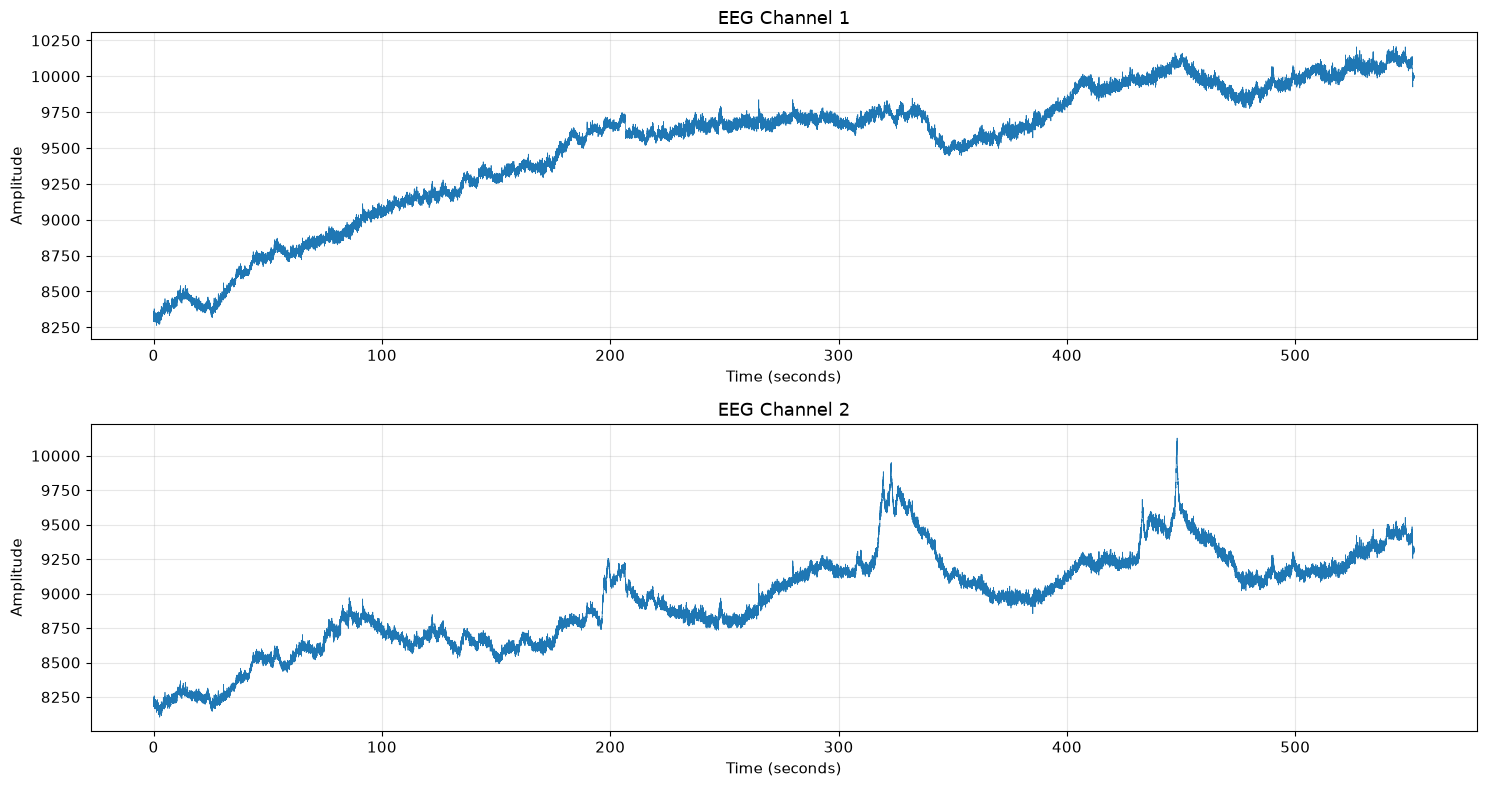

In [6]:
eeg_1 = trial["eeg_1"].dropna().to_numpy()
eeg_2 = trial["eeg_2"].dropna().to_numpy()

time_eeg_1 = np.arange(len(eeg_1)) / EEG_FS
time_eeg_2 = np.arange(len(eeg_2)) / EEG_FS

fig, axes = plt.subplots(2, 1, figsize=(15, 8))

axes[0].plot(time_eeg_1, eeg_1, linewidth=0.5)
axes[0].set_title("EEG Channel 1")
axes[0].set_ylabel("Amplitude")
axes[0].set_xlabel("Time (seconds)")
axes[0].grid(alpha=0.3)

axes[1].plot(time_eeg_2, eeg_2, linewidth=0.5)
axes[1].set_title("EEG Channel 2")
axes[1].set_ylabel("Amplitude")
axes[1].set_xlabel("Time (seconds)")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

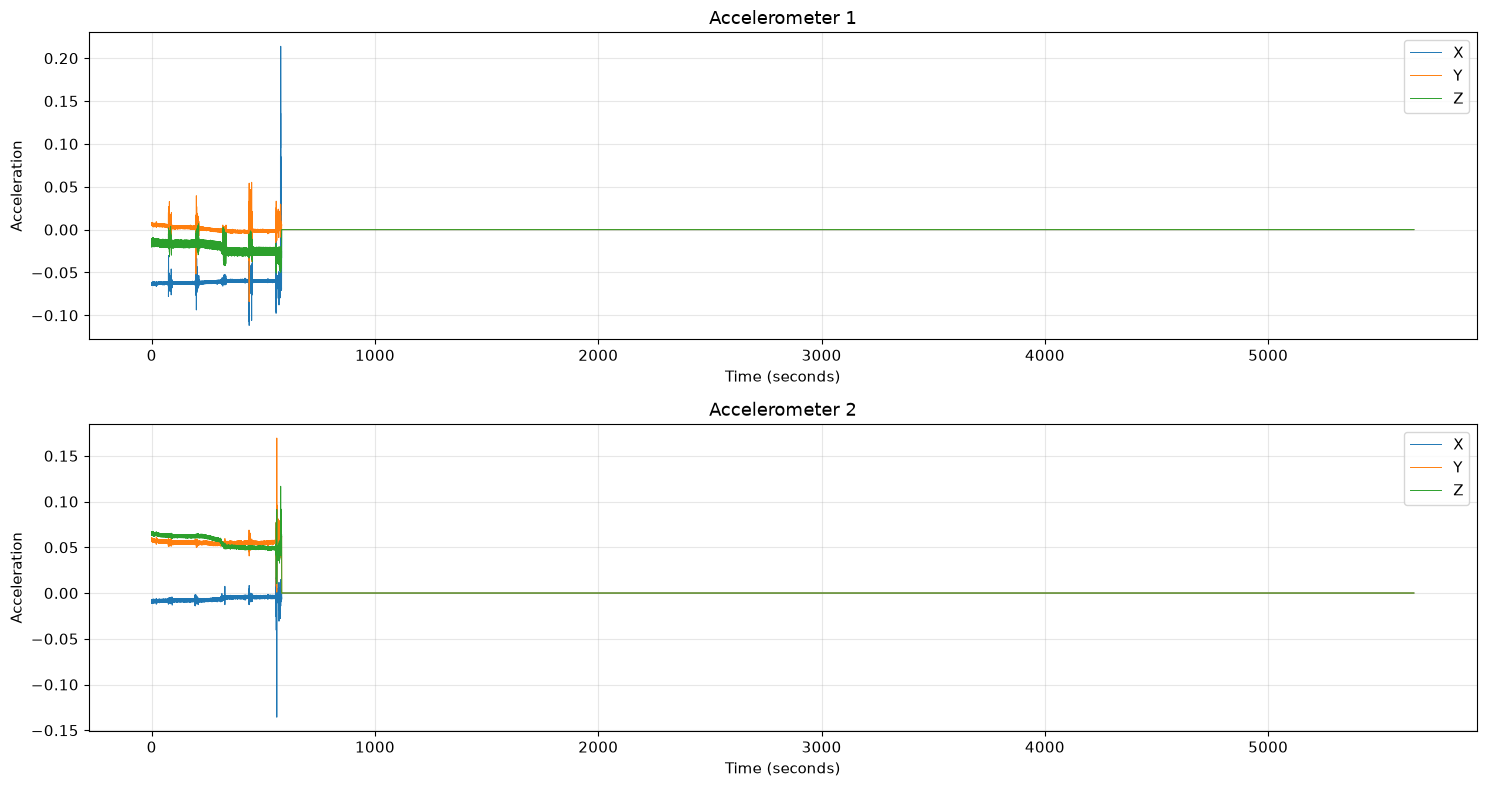

In [7]:
accelerometer_1 = trial[
    ["accel_1_x", "accel_1_y", "accel_1_z"]
].dropna()

accelerometer_2 = trial[
    ["accel_2_x", "accel_2_y", "accel_2_z"]
].dropna()

time_accel_1 = np.arange(len(accelerometer_1)) / ACC_FS
time_accel_2 = np.arange(len(accelerometer_2)) / ACC_FS

fig, axes = plt.subplots(2, 1, figsize=(15, 8))

for axis in ["x", "y", "z"]:
    axes[0].plot(
        time_accel_1,
        accelerometer_1[f"accel_1_{axis}"],
        label=axis.upper(),
        linewidth=0.7
    )

    axes[1].plot(
        time_accel_2,
        accelerometer_2[f"accel_2_{axis}"],
        label=axis.upper(),
        linewidth=0.7
    )

axes[0].set_title("Accelerometer 1")
axes[1].set_title("Accelerometer 2")

for ax in axes:
    ax.set_xlabel("Time (seconds)")
    ax.set_ylabel("Acceleration")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

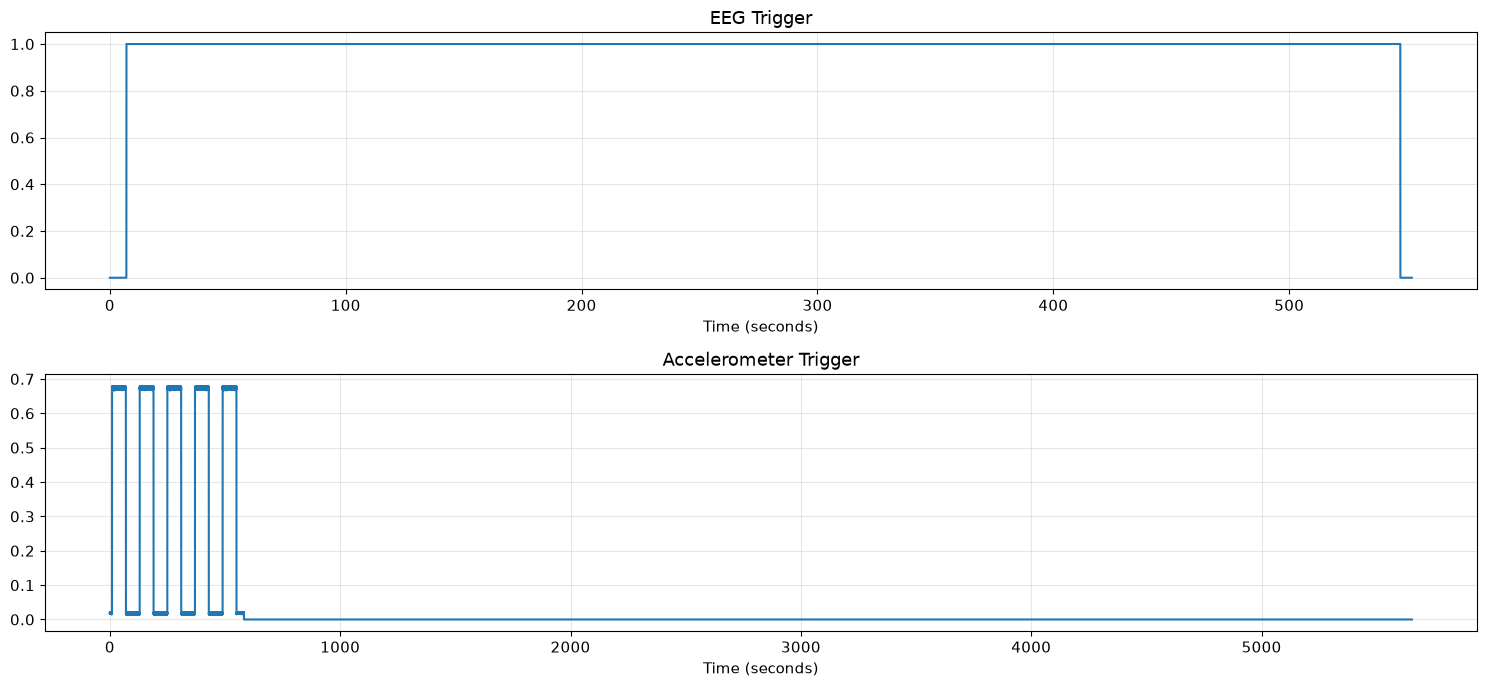

In [8]:
eeg_trigger = trial["eeg_trigger"].dropna().to_numpy()
accel_trigger = trial["accel_trigger"].dropna().to_numpy()

fig, axes = plt.subplots(2, 1, figsize=(15, 7))

axes[0].plot(
    np.arange(len(eeg_trigger)) / EEG_FS,
    eeg_trigger
)
axes[0].set_title("EEG Trigger")
axes[0].set_xlabel("Time (seconds)")
axes[0].grid(alpha=0.3)

axes[1].plot(
    np.arange(len(accel_trigger)) / ACC_FS,
    accel_trigger
)
axes[1].set_title("Accelerometer Trigger")
axes[1].set_xlabel("Time (seconds)")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [9]:
eeg_duration = len(eeg_1) / EEG_FS
accel_duration_1 = len(accelerometer_1) / ACC_FS
accel_duration_2 = len(accelerometer_2) / ACC_FS

print("RECORDING DURATIONS")
print("----------------------------")
print(f"EEG Channel 1: {eeg_duration:.2f} seconds")
print(f"Accelerometer 1: {accel_duration_1:.2f} seconds")
print(f"Accelerometer 2: {accel_duration_2:.2f} seconds")

RECORDING DURATIONS
----------------------------
EEG Channel 1: 552.00 seconds
Accelerometer 1: 5652.48 seconds
Accelerometer 2: 5652.48 seconds
